In [10]:
from datasets import load_dataset
import numpy as np
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

In [3]:
dataset = load_dataset(
    "McAuley-Lab/Amazon-Reviews-2023",
    "raw_meta_Electronics",
    split="full"
)

Using the latest cached version of the dataset since McAuley-Lab/Amazon-Reviews-2023 couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'raw_meta_Electronics' at /Users/tusharrohilla/.cache/huggingface/datasets/McAuley-Lab___amazon-reviews-2023/raw_meta_Electronics/0.0.0/16b76e0823d73bb8cff1e9c5e3e37dbc46ae3daee380417ae141f5e67d3ea8e8 (last modified on Tue Aug  4 08:05:44 2026).


In [4]:
df = dataset.to_pandas()

In [5]:
df.shape

(1610012, 16)

In [6]:
df.head()

,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together,subtitle,author
0,All Electronics,FS-1051 FATSHARK TELEPORTER V3 HEADSET,3.5,6,[],[Teleporter V3 The “Teleporter V3” kit sets a ...,None,"{'hi_res': [None], 'large': ['https://m.media-...","{'title': [], 'url': [], 'user_id': []}",Fat Shark,"[Electronics, Television & Video, Video Glasses]","{""Date First Available"": ""August 2, 2014"", ""Ma...",B00MCW7G9M,NaN,NaN,NaN
1,All Electronics,Ce-H22B12-S1 4Kx2K Hdmi 4Port,5.0,1,"[UPC: 662774021904, Weight: 0.600 lbs]",[HDMI In - HDMI Out],None,{'hi_res': ['https://m.media-amazon.com/images...,"{'title': [], 'url': [], 'user_id': []}",SIIG,"[Electronics, Television & Video, Accessories,...","{""Product Dimensions"": ""0.83 x 4.17 x 2.05 inc...",B00YT6XQSE,NaN,NaN,NaN
2,Computers,Digi-Tatoo Decal Skin Compatible With MacBook ...,4.5,246,[WARNING: Please IDENTIFY MODEL NUMBER on the ...,[],19.99,{'hi_res': ['https://m.media-amazon.com/images...,"{'title': ['AL 2Sides Video', 'MacBook Protect...",Digi-Tatoo,"[Electronics, Computers & Accessories, Laptop ...","{""Brand"": ""Digi-Tatoo"", ""Color"": ""Fresh Marble...",B07SM135LS,NaN,NaN,NaN
3,AMAZON FASHION,NotoCity Compatible with Vivoactive 4 band 22m...,4.5,233,[☛NotoCity 22mm band is designed for Vivoactiv...,[],9.99,{'hi_res': ['https://m.media-amazon.com/images...,"{'title': [], 'url': [], 'user_id': []}",NotoCity,"[Electronics, Wearable Technology, Clips, Arm ...","{""Date First Available"": ""May 29, 2020"", ""Manu...",B089CNGZCW,NaN,NaN,NaN
4,Cell Phones & Accessories,Motorola Droid X Essentials Combo Pack,3.8,64,"[New Droid X Essentials Combo Pack, Exclusive ...",[all Genuine High Quality Motorola Made Access...,14.99,"{'hi_res': [None, None, None, None, None], 'la...","{'title': [], 'url': [], 'user_id': []}",Verizon,"[Electronics, Computers & Accessories, Compute...","{""Product Dimensions"": ""11.6 x 6.9 x 3.1 inche...",B004E2Z88O,NaN,NaN,NaN


In [7]:
def get_image_url(images):
    """Return the first available image URL."""

    if not isinstance(images, dict):
        return None

    for key in ["large", "hi_res", "thumb"]:
        urls = images.get(key)

        if urls is None:
            continue

        # Convert numpy array to list
        if isinstance(urls, np.ndarray):
            urls = urls.tolist()

        for url in urls:
            if url is not None and url != "":
                return url

    return None

Title      : iPhone 8 Lightning Adapter Headphone Metal Case Headphone Audio Adapter 2.4A Quick Charge Earphones Splitter - compatible with IOS 11 ZERKAR (Black-lightning^)
Brand      : zerkar
Category   : Electronics > Car & Vehicle Electronics > Car Electronics
Price      : None
Rating     : 4.5 (4 ratings)



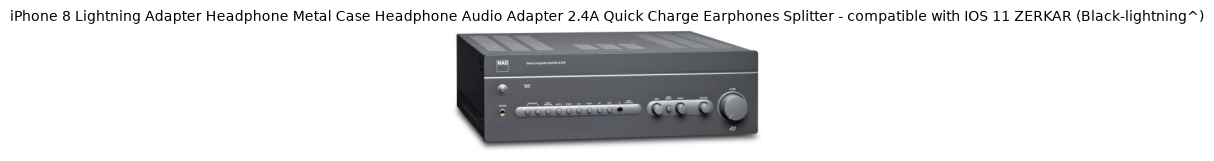

Title      : Gear4 Angry Birds SpaceTouch Case for iPod 4G - Fire Bomb Bird
Brand      : Gear4
Category   : Electronics > Portable Audio & Video > MP3 & MP4 Player Accessories > Cases
Price      : None
Rating     : 4.4 (6 ratings)



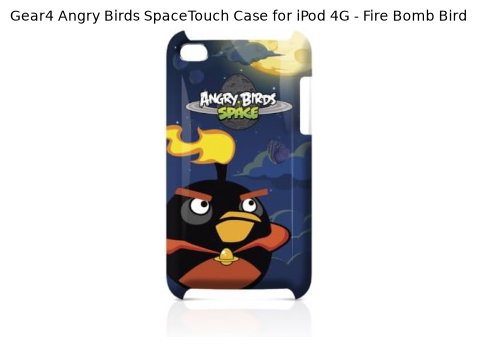

Title      : Surface Pro 9 Pro 8 Docking Station Hub with 4K HDMI, Full-Function Type C (Display+10Gbps Data+100W PD Charging), 100M Ethernet,USB3.0,Type C Data Audio SD/TF Card Slot for Microsoft Surface Pro 9/8
Brand      : Rocketek
Category   : Electronics > Computers & Accessories > Laptop Accessories > Docking Stations
Price      : 39.99
Rating     : 3.9 (29 ratings)



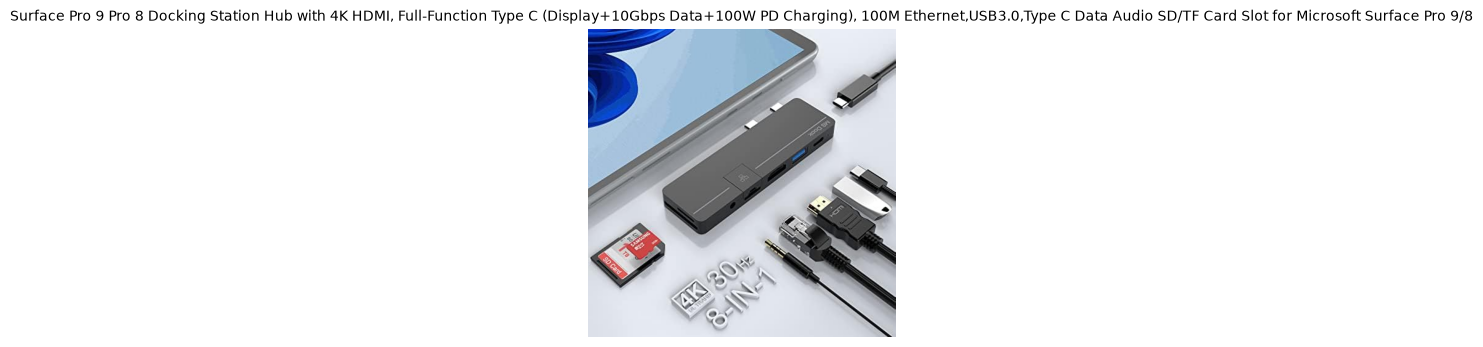

Title      : DriSentri 120W Speaker 3 Way Audio Frequency Divider Loudspeaker 3 Unit Crossover Filters for Speakers
Brand      : DriSentri
Category   : Electronics > Home Audio > Home Audio Accessories > Home Audio Crossovers & Parts > Crossover Parts
Price      : 9.99
Rating     : 4.1 (13 ratings)



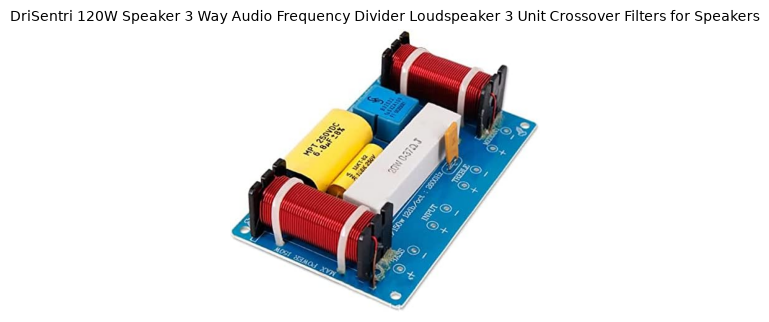

Title      : USB Bluetooth 4.0 Adapter Dongle for PC Laptop Computer Desktop Stereo Music Skype Call Keyboard Mouse Support All Windows XP Vista 7 8 Win 10
Brand      : ACSUN
Category   : 
Price      : None
Rating     : 3.7 (9 ratings)



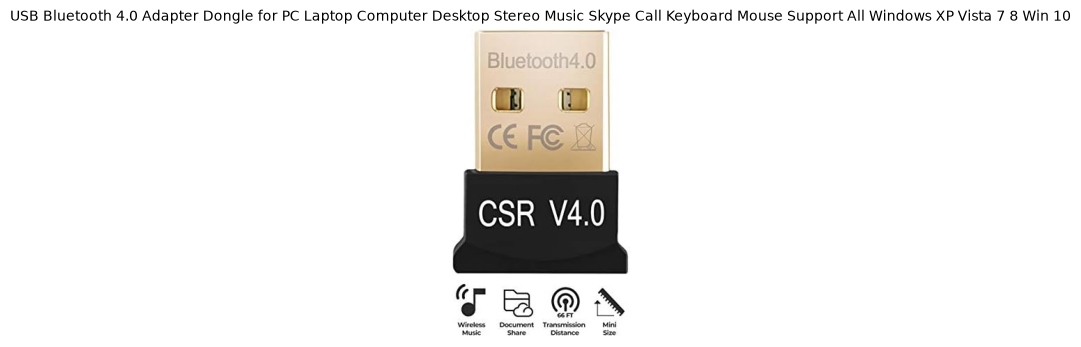

In [11]:
# Randomly sample 5 products
sample_df = df.sample(n=5, random_state=42).reset_index(drop=True)

for _, row in sample_df.iterrows():

    print("=" * 100)
    print(f"Title      : {row['title']}")
    print(f"Brand      : {row['store']}")

    categories = row["categories"]
    if not isinstance(categories, list):
        categories = list(categories)

    print(f"Category   : {' > '.join(categories)}")
    print(f"Price      : {row['price']}")
    print(f"Rating     : {row['average_rating']} ({row['rating_number']} ratings)")
    print()

    image_url = get_image_url(row["images"])

    if image_url is None:
        print("No image available.")
        continue

    try:
        response = requests.get(image_url, timeout=10)
        response.raise_for_status()

        img = Image.open(BytesIO(response.content))

        plt.figure(figsize=(4, 4))
        plt.imshow(img)
        plt.title(row["title"], fontsize=10)
        plt.axis("off")
        plt.show()

    except Exception as e:
        print(f"Could not load image: {e}")